In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import BayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator, ExpectationMaximization
from pgmpy.estimators import AIC, BIC,K2
from pgmpy.inference import VariableElimination, BeliefPropagation

ImportError: cannot import name 'AIC' from 'pgmpy.estimators' (c:\Users\gidle\AppData\Local\Programs\Python\Python311\Lib\site-packages\pgmpy\estimators\__init__.py)

In [ ]:
train = pd.read_csv("data/train.csv")
store = pd.read_csv("data/store.csv")

df = train.merge(store, on="Store", how="left")

df.head()

/var/folders/l5/lx0hst652c9b_0d40_sg9wyr0000gn/T/ipykernel_16204/3216638756.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("data/train.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [ ]:
df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval'],
      dtype='object')

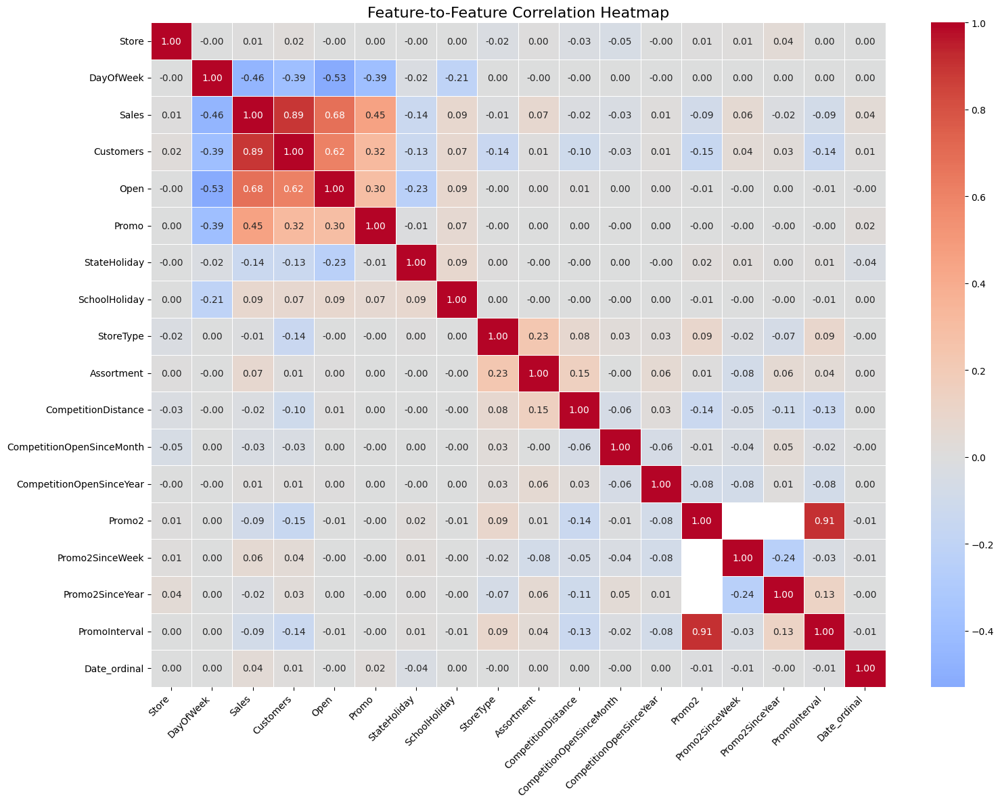

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 复制一份，避免改原数据
heatmap_data = df.copy()

# 日期列转成数值
if "Date" in heatmap_data.columns:
    heatmap_data["Date"] = pd.to_datetime(heatmap_data["Date"])
    heatmap_data["Date_ordinal"] = heatmap_data["Date"].map(pd.Timestamp.toordinal)
    heatmap_data = heatmap_data.drop(columns=["Date"])

# 把非数值列编码成 category codes
for col in heatmap_data.columns:
    if heatmap_data[col].dtype == "object" or str(heatmap_data[col].dtype) == "category":
        heatmap_data[col] = heatmap_data[col].astype("category").cat.codes

# 计算相关系数矩阵
corr_matrix = heatmap_data.corr()

# 画热力图
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Feature-to-Feature Correlation Heatmap", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================
# Cell 4: Basic preprocessing preparation
# ==============================

# Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Convert Date into month-level category for Bayesian Network
# Keep the column name as "Date" as required
df["Date"] = df["Date"].dt.month

# Make StateHoliday consistent as string
df["StateHoliday"] = df["StateHoliday"].astype(str)

# Check selected variables
selected_cols = [
    "Date",
    "Promo",
    "Customers",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "Open",
    "CompetitionDistance",
    "Sales",
    "Assortment"
]

df[selected_cols].head()

,Date,Promo,Customers,DayOfWeek,StateHoliday,SchoolHoliday,Open,CompetitionDistance,Sales,Assortment
0,7,1,555,5,0,1,1,1270.0,5263,a
1,7,1,625,5,0,1,1,570.0,6064,a
2,7,1,821,5,0,1,1,14130.0,8314,a
3,7,1,1498,5,0,1,1,620.0,13995,c
4,7,1,559,5,0,1,1,29910.0,4822,a


In [ ]:
# ==============================
# Cell 5: Select variables and check missing values before discretisation
# ==============================

selected_cols = [
    "Promo",
    "Customers",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "Open",
    "CompetitionDistance",
    "Sales",
    "Assortment"
]

raw_bn_df = df[selected_cols].copy()

print("Missing values before discretisation:")
print(raw_bn_df.isna().sum())

print("\nTotal missing values before discretisation:")
print(raw_bn_df.isna().sum().sum())

Missing values before discretisation:
Promo                     0
Customers                 0
DayOfWeek                 0
StateHoliday              0
SchoolHoliday             0
Open                      0
CompetitionDistance    2642
Sales                     0
Assortment                0
dtype: int64

Total missing values before discretisation:
2642


In [ ]:
# ==============================
# Cell 6: Handle missing CompetitionDistance by dropping missing rows
# ==============================

print("Missing CompetitionDistance before dropping:")
print(raw_bn_df["CompetitionDistance"].isna().sum())

rows_before = len(raw_bn_df)

# Drop rows where CompetitionDistance is missing
raw_bn_df = raw_bn_df.dropna(subset=["CompetitionDistance"]).copy()

rows_after = len(raw_bn_df)

print("\nMissing CompetitionDistance after dropping:")
print(raw_bn_df["CompetitionDistance"].isna().sum())

print("\nRows before dropping:", rows_before)
print("Rows after dropping:", rows_after)
print("Dropped rows:", rows_before - rows_after)

Missing CompetitionDistance before dropping:
2642

Missing CompetitionDistance after dropping:
0

Rows before dropping: 1017209
Rows after dropping: 1014567
Dropped rows: 2642


In [ ]:
# ==============================
# Cell 8: Discretisation without changing column names
# ==============================

bn_data = raw_bn_df.copy()

# Discretise Customers into Low / Medium / High
bn_data["Customers"] = pd.qcut(
    bn_data["Customers"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

# Discretise Sales into Low / Medium / High
bn_data["Sales"] = pd.qcut(
    bn_data["Sales"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

# Discretise CompetitionDistance into Near / Medium / Far
bn_data["CompetitionDistance"] = pd.qcut(
    bn_data["CompetitionDistance"],
    q=3,
    labels=["Near", "Medium", "Far"],
    duplicates="drop"
)

# Convert all variables into category type
for col in bn_data.columns:
    bn_data[col] = bn_data[col].astype("category")

bn_data.head()

,Promo,Customers,DayOfWeek,StateHoliday,SchoolHoliday,Open,CompetitionDistance,Sales,Assortment
0,1,Medium,5,0,1,1,Medium,Medium,a
1,1,Medium,5,0,1,1,Near,Medium,a
2,1,High,5,0,1,1,Far,High,a
3,1,High,5,0,1,1,Near,High,c
4,1,Medium,5,0,1,1,Far,Medium,a


In [ ]:
# ==============================
# Create bin settings for bin plots
# ==============================

import numpy as np
import pandas as pd
import plotly.express as px

bin_settings = {}

# Customers bins
_, customers_bins = pd.qcut(
    raw_bn_df["Customers"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop",
    retbins=True
)

bin_settings["Customers"] = {
    "bins": customers_bins,
    "labels": ["Low", "Medium", "High"]
}

# Sales bins
_, sales_bins = pd.qcut(
    raw_bn_df["Sales"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop",
    retbins=True
)

bin_settings["Sales"] = {
    "bins": sales_bins,
    "labels": ["Low", "Medium", "High"]
}

# CompetitionDistance bins
_, competition_bins = pd.qcut(
    raw_bn_df["CompetitionDistance"],
    q=3,
    labels=["Near", "Medium", "Far"],
    duplicates="drop",
    retbins=True
)

bin_settings["CompetitionDistance"] = {
    "bins": competition_bins,
    "labels": ["Near", "Medium", "Far"]
}

bin_settings

{'Customers': {'bins': array([   0.,  485.,  748., 7388.]),
  'labels': ['Low', 'Medium', 'High']},
 'Sales': {'bins': array([    0.,  4520.,  7048., 41551.]),
  'labels': ['Low', 'Medium', 'High']},
 'CompetitionDistance': {'bins': array([2.000e+01, 1.160e+03, 4.520e+03, 7.586e+04]),
  'labels': ['Near', 'Medium', 'Far']}}

In [ ]:
# ==============================
# Binning plots for discretised variables
# ==============================

colors_blue = ["#132C33", "#264D58", "#17869E", "#51C4D3", "#B4DBE9"]
colors_dark = ["#1F1F1F", "#313131", "#636363", "#AEAEAE", "#DADADA"]
colors_green = ["#01411C", "#4B6F44", "#4F7942", "#74C365", "#D0F0C0"]

for feature in bin_settings.keys():
    temp = pd.DataFrame({
        feature: raw_bn_df[feature],
        "Bin Category": bn_data[feature].astype(str)
    }).dropna()

    fig = px.histogram(
        temp,
        x=feature,
        color="Bin Category",
        nbins=60,
        opacity=0.75,
        marginal="box",
        template="plotly_white",
        color_discrete_sequence=[
            colors_blue[2],
            colors_green[3],
            colors_blue[4],
            colors_green[1],
            colors_dark[3]
        ]
    )

    boundaries = bin_settings[feature]["bins"][1:-1]

    for b in boundaries:
        if np.isfinite(b):
            fig.add_vline(
                x=b,
                line_width=1,
                line_dash="dot",
                line_color=colors_dark[1],
                opacity=0.8
            )

            fig.add_annotation(
                x=b,
                y=1,
                yref="paper",
                text=f"Boundary = {b:.2f}",
                showarrow=False,
                font_size=10,
                font_family="monospace",
                bgcolor="white"
            )

    fig.update_layout(
        font_family="monospace",
        title=dict(
            text=f"{feature} Discretisation / Binning Plot",
            x=0.5,
            y=0.95,
            font=dict(color=colors_dark[2], size=22)
        ),
        xaxis_title_text=feature,
        yaxis_title_text="Count",
        legend_title_text="Bin Category",
        bargap=0.25
    )

    fig.show()

In [ ]:
# ==============================
# Count plots for categorical variables
# ==============================

categorical_features = [
    "Open",
    "Promo",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "Assortment"
]

for feature in categorical_features:
    temp = bn_data[feature].astype(str).value_counts().reset_index()
    temp.columns = [feature, "Count"]

    fig = px.bar(
        temp,
        x=feature,
        y="Count",
        template="plotly_white",
        color=feature,
        color_discrete_sequence=[
            colors_blue[2],
            colors_green[3],
            colors_blue[4],
            colors_green[1],
            colors_dark[3]
        ]
    )

    fig.update_layout(
        font_family="monospace",
        title=dict(
            text=f"{feature} Category Distribution",
            x=0.5,
            y=0.95,
            font=dict(color=colors_dark[2], size=22)
        ),
        xaxis_title_text=feature,
        yaxis_title_text="Count",
        showlegend=False
    )

    fig.show()

In [ ]:
# ==============================
# Cell 9: Final data check after discretisation
# ==============================

print("Final missing values:")
print(bn_data.isna().sum())

print("\nTotal final missing values:")
print(bn_data.isna().sum().sum())

print("\nData types:")
print(bn_data.dtypes)

print("\nShape of final bn_data:")
print(bn_data.shape)

Final missing values:
Promo                  0
Customers              0
DayOfWeek              0
StateHoliday           0
SchoolHoliday          0
Open                   0
CompetitionDistance    0
Sales                  0
Assortment             0
dtype: int64

Total final missing values:
0

Data types:
Promo                  category
Customers              category
DayOfWeek              category
StateHoliday           category
SchoolHoliday          category
Open                   category
CompetitionDistance    category
Sales                  category
Assortment             category
dtype: object

Shape of final bn_data:
(1014567, 9)
